# CSA0812 – Assignment 3, Q4
## Sets: Elective Registration Clash Detection

**Student:** Darshan A  
**Register Number:** 1973260011

### Aim
Use sets to identify students registered in both electives, exactly one elective, and neither elective. Remove duplicate registrations, produce sorted reports, draw Venn-style diagrams, and compare set operations with list-based approaches.

### Prediction
Set membership and set intersection should be faster on average than scanning lists or using nested loops. Sets automatically remove duplicate register numbers and provide average O(n + m) set operations, at the cost of not preserving duplicate entries or list order.

## 1. Complete the given code (TODO 1)

The program uses set operators to find the intersection, symmetric difference and difference from the full student set.

In [1]:
ai_elective = {"192311001", "192311004", "192311007", "192311009"}
iot_elective = {"192311002", "192311004", "192311009", "192311010"}
all_students = {f"1923110{i:02d}" for i in range(1, 11)}

# TODO 1: use set operators
both = ai_elective & iot_elective
exactly_one = ai_elective ^ iot_elective
neither = all_students - (ai_elective | iot_elective)

print("clash :", sorted(both))
print("exactly one:", sorted(exactly_one))
print("neither :", sorted(neither))

# Required rewrite using set methods
both_method = ai_elective.intersection(iot_elective)
exactly_one_method = ai_elective.symmetric_difference(iot_elective)
neither_method = all_students.difference(ai_elective.union(iot_elective))

assert both == both_method
assert exactly_one == exactly_one_method
assert neither == neither_method
print("Set operator and set method results match:", True)

clash : ['192311004', '192311009']
exactly one: ['192311001', '192311002', '192311007', '192311010']
neither : ['192311003', '192311005', '192311006', '192311008']
Set operator and set method results match: True


## 2. Duplicate removal and small-case hand verification

A set stores each distinct value only once. The small example is checked by listing the expected overlap and non-overlap manually.

In [2]:
# Duplicate registrations are automatically removed
registrations_with_duplicates = [
    "STU01", "STU02", "STU01", "STU03", "STU02"
]
unique_registrations = set(registrations_with_duplicates)
print("Original registrations:", registrations_with_duplicates)
print("Set after duplicate removal:", sorted(unique_registrations))

# Small hand-checkable example
small_a = {"A", "B", "C"}
small_b = {"B", "C", "D"}
small_all = {"A", "B", "C", "D", "E"}

small_both = small_a & small_b
small_one = small_a ^ small_b
small_neither = small_all - (small_a | small_b)

print("Small case - both:", sorted(small_both))
print("Small case - exactly one:", sorted(small_one))
print("Small case - neither:", sorted(small_neither))

assert small_both == {"B", "C"}
assert small_one == {"A", "D"}
assert small_neither == {"E"}
print("Small-case hand verification passed.")

Original registrations: ['STU01', 'STU02', 'STU01', 'STU03', 'STU02']
Set after duplicate removal: ['STU01', 'STU02', 'STU03']
Small case - both: ['B', 'C']
Small case - exactly one: ['A', 'D']
Small case - neither: ['E']
Small-case hand verification passed.


## 3. Venn diagrams for the three reports

The diagrams show the overlap (both electives), the two non-overlapping regions (exactly one), and the outside region (neither).

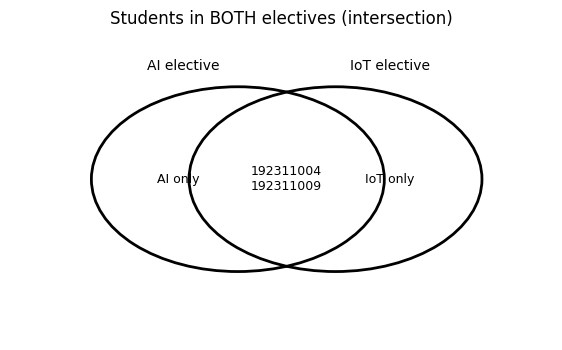

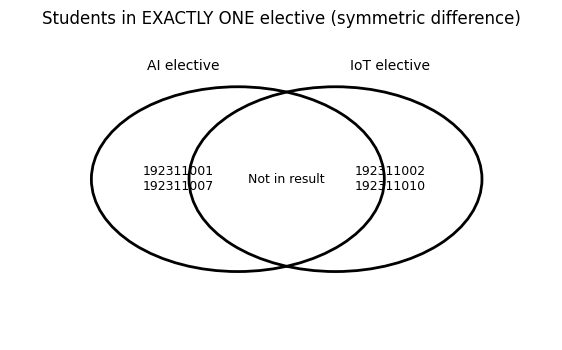

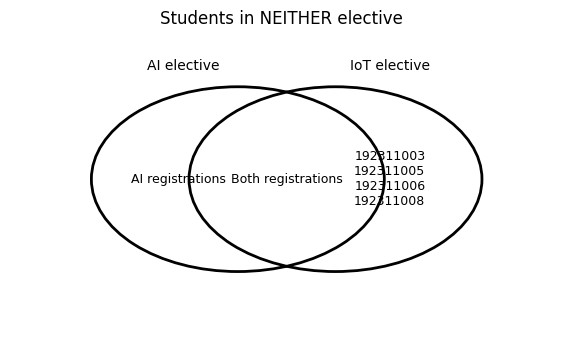

In [3]:
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, Rectangle

def draw_venn(title, left_text, right_text, outside_text):
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.add_patch(Circle((0.42, 0.52), 0.27, fill=False, linewidth=2))
    ax.add_patch(Circle((0.60, 0.52), 0.27, fill=False, linewidth=2))
    ax.text(0.31, 0.52, left_text, ha="center", va="center", fontsize=9)
    ax.text(0.51, 0.52, right_text, ha="center", va="center", fontsize=9)
    ax.text(0.70, 0.52, outside_text, ha="center", va="center", fontsize=9)
    ax.text(0.32, 0.84, "AI elective", ha="center")
    ax.text(0.70, 0.84, "IoT elective", ha="center")
    ax.set_title(title)
    ax.set_xlim(0, 1)
    ax.set_ylim(0.05, 0.95)
    ax.axis("off")
    plt.show()

draw_venn(
    "Students in BOTH electives (intersection)",
    "AI only", "\n".join(sorted(both)) or "None", "IoT only"
)
draw_venn(
    "Students in EXACTLY ONE elective (symmetric difference)",
    "\n".join(sorted(ai_elective - iot_elective)) or "None",
    "Not in result", "\n".join(sorted(iot_elective - ai_elective)) or "None"
)
draw_venn(
    "Students in NEITHER elective",
    "AI registrations", "Both registrations", "\n".join(sorted(neither)) or "None"
)

## 4. Membership experiment: list versus set

Measure membership checks for 10,000, 100,000 and 1,000,000 register numbers. Each test checks for the last element, making the list search a worst-position scan while set lookup uses hashing. Median of five runs is reported.

In [4]:
import time
import statistics

def median_membership_time(container, target, repeats=5, checks=200):
    samples = []
    for _ in range(repeats):
        start = time.perf_counter()
        found = False
        for _ in range(checks):
            found = target in container
        samples.append(time.perf_counter() - start)
    return statistics.median(samples), found

membership_results = []

for size in (10_000, 100_000, 1_000_000):
    numbers = [f"REG{i:07d}" for i in range(size)]
    number_set = set(numbers)
    target = numbers[-1]  # last list item: worst-position list scan

    list_time, list_found = median_membership_time(numbers, target)
    set_time, set_found = median_membership_time(number_set, target)

    assert list_found and set_found
    membership_results.append({
        "Register numbers": size,
        "List membership (s)": list_time,
        "Set membership (s)": set_time,
        "Results match": list_found == set_found
    })

print("Membership benchmark (median of 5 runs, 200 checks each):")
for result in membership_results:
    print(result)

Membership benchmark (median of 5 runs, 200 checks each):
{'Register numbers': 10000, 'List membership (s)': 0.06540837099998953, 'Set membership (s)': 1.027000001840861e-05, 'Results match': True}
{'Register numbers': 100000, 'List membership (s)': 0.9705820650000305, 'Set membership (s)': 8.91299998784234e-06, 'Results match': True}
{'Register numbers': 1000000, 'List membership (s)': 4.2619660579999845, 'Set membership (s)': 1.0431000021071668e-05, 'Results match': True}


## 5. Finding common students: nested loops versus set intersection

Nested loops compare every item in one list with every item in the other (O(n·m)). The set `&` operation takes O(n + m) average time. A moderate input is used for the nested-loop timing to keep the notebook practical; the set operation is measured on the same data.

In [5]:
def common_nested(list_a, list_b):
    common = set()
    for a in list_a:
        for b in list_b:
            if a == b:
                common.add(a)
    return common

def common_with_sets(list_a, list_b):
    return set(list_a) & set(list_b)

# 2,000 x 2,000 comparisons for nested-loop demonstration
left_list = [f"STU{i:05d}" for i in range(2000)]
right_list = [f"STU{i:05d}" for i in range(1000, 3000)]

start = time.perf_counter()
nested_result = common_nested(left_list, right_list)
nested_time = time.perf_counter() - start

start = time.perf_counter()
set_result = common_with_sets(left_list, right_list)
set_time = time.perf_counter() - start

print("Nested-loop common count:", len(nested_result))
print("Set intersection common count:", len(set_result))
print("Results match:", nested_result == set_result)
print("Nested-loop time:", round(nested_time, 6), "seconds")
print("Set intersection time:", round(set_time, 6), "seconds")

Nested-loop common count: 1000
Set intersection common count: 1000
Results match: True
Nested-loop time: 0.201981 seconds
Set intersection time: 0.000731 seconds


## 6. Empty and identical elective tests

In [6]:
# Empty electives
empty_a = set()
empty_b = set()
print("Empty - both:", sorted(empty_a & empty_b))
print("Empty - exactly one:", sorted(empty_a ^ empty_b))
print("Empty - neither from all_students:", sorted(all_students - (empty_a | empty_b)))

# Identical electives
same_a = {"S1", "S2", "S3"}
same_b = {"S1", "S2", "S3"}
print("Identical - both:", sorted(same_a & same_b))
print("Identical - exactly one:", sorted(same_a ^ same_b))
print("Identical - neither:", sorted({"S1", "S2", "S3", "S4"} - (same_a | same_b)))

assert same_a & same_b == same_a
assert same_a ^ same_b == set()
assert empty_a & empty_b == set()
print("Empty and identical elective tests passed.")

Empty - both: []
Empty - exactly one: []
Empty - neither from all_students: ['192311001', '192311002', '192311003', '192311004', '192311005', '192311006', '192311007', '192311008', '192311009', '192311010']
Identical - both: ['S1', 'S2', 'S3']
Identical - exactly one: []
Identical - neither: ['S4']
Empty and identical elective tests passed.


## 7. Design and analysis

- **Duplicates:** A set stores unique hashable elements, so adding a register number already present does not create another copy.
- **Membership:** `x in set` uses hashing and is O(1) on average. `x in list` scans elements and is O(n) in the worst case.
- **Hashable elements:** Lists are mutable and unhashable, so they cannot be set elements. Tuples can be set elements when all their contents are hashable.
- **Set operators:** `A | B` is union, `A & B` is intersection, `A - B` is difference, and `A ^ B` is symmetric difference.
- **Dictionary/set ordering:** Sets are unordered; sorting is used to produce stable reports.
- **Information lost on conversion:** Converting a list to a set removes duplicates and does not preserve the original list order or positional information.

### Alternative approaches and complexity
1. **Nested loops:** compare each of n elements with each of m elements. Time O(n·m); additional output space O(k), where k is the number of common elements.
2. **Sort and merge:** sort both lists, then walk through them with two pointers. Time O(n log n + m log m); extra space depends on whether sorting is in place and on the output.
3. **Sets:** build/hash the collections and use intersection. Expected time O(n + m); extra space O(n + m) for the converted sets and up to O(k) for the result.

### Conclusion
Convert a list to a set before processing when duplicate removal and fast membership or set operations are needed. Do not convert if duplicate counts, original ordering or positional information must be retained.